In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
)

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('student_performance.csv')
df.shape

(500, 9)

# Data Analysis

In [ ]:
df.head()

,student_id,study_hours_week,attendance_pct,prev_gpa,sleep_hours,assignments_done_pct,part_time_job,final_score,passed
0,S001,11.2,96.4,2.86,6.1,66.9,0,73.5,1
1,S002,5.8,90.7,2.46,6.1,63.0,0,52.9,0
2,S003,13.0,71.4,2.65,8.4,82.8,0,74.2,1
3,S004,13.8,62.0,3.28,7.2,79.5,0,68.2,1
4,S005,2.2,44.4,2.90,6.5,49.7,0,39.9,0


In [ ]:
df.info()
    #There are missing values in prev_gpa and sleep_hours columns. (both are numirical)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            500 non-null    object 
 1   study_hours_week      500 non-null    float64
 2   attendance_pct        500 non-null    float64
 3   prev_gpa              487 non-null    float64
 4   sleep_hours           483 non-null    float64
 5   assignments_done_pct  500 non-null    float64
 6   part_time_job         500 non-null    int64  
 7   final_score           500 non-null    float64
 8   passed                500 non-null    int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 35.3+ KB


In [ ]:
print("\nMissing values per column:")
print(df.isna().sum())


Missing values per column:
student_id               0
study_hours_week         0
attendance_pct           0
prev_gpa                13
sleep_hours             17
assignments_done_pct     0
part_time_job            0
final_score              0
passed                   0
dtype: int64


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
study_hours_week,500.0,9.948600,3.838130,0.00,7.300,10.00,12.325,21.7
attendance_pct,500.0,79.276200,11.827510,36.20,71.325,80.10,87.175,100.0
prev_gpa,487.0,2.898111,0.595107,1.13,2.510,2.90,3.305,4.0
sleep_hours,483.0,6.611801,1.200435,3.10,5.850,6.70,7.400,10.0
assignments_done_pct,500.0,74.197600,16.866799,19.90,62.475,75.70,86.900,100.0
part_time_job,500.0,0.356000,0.479295,0.00,0.000,0.00,1.000,1.0
final_score,500.0,59.590600,9.914505,23.40,53.800,60.25,66.800,87.5
passed,500.0,0.700000,0.458717,0.00,0.000,1.00,1.000,1.0


In [ ]:
X = df.drop(columns=['student_id', 'passed', 'final_score'])
y_reg = df['final_score']
y_class = df['passed']

# Data Visualization

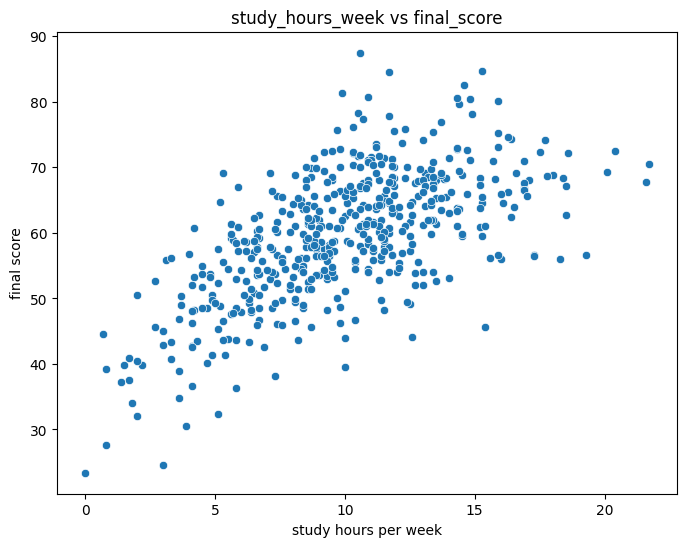

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='study_hours_week', y='final_score')
plt.title('study_hours_week vs final_score')
plt.xlabel('study hours per week')
plt.ylabel('final score')
plt.show()

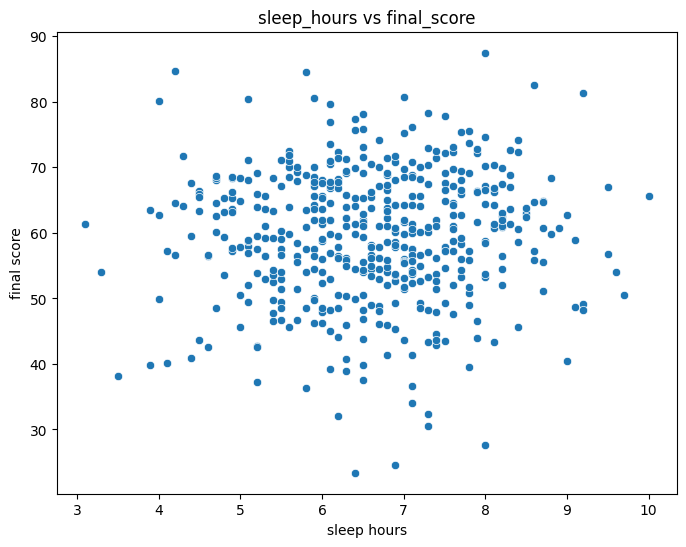

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='sleep_hours', y='final_score')
plt.title('sleep_hours vs final_score')
plt.xlabel('sleep hours')
plt.ylabel('final score')
plt.show()

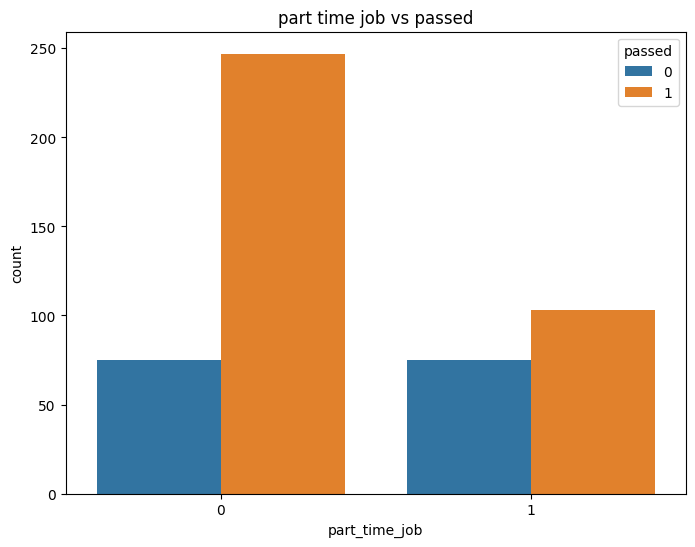

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='part_time_job', hue='passed')
plt.title('part time job vs passed')
plt.legend(title='passed')
plt.show()

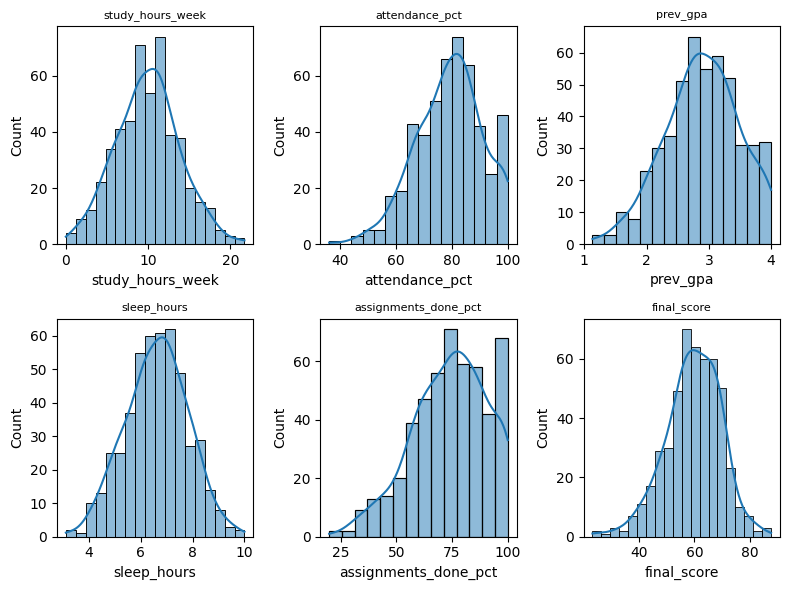

In [ ]:
num_cols = df.drop(columns=['student_id','part_time_job', 'passed'])
fig, axes = plt.subplots(2, 3, figsize=(8, 6))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
numeric_df = df.drop(columns=['student_id','part_time_job', 'passed'])
corr_with_target = numeric_df.corr()['final_score'].sort_values(ascending=False)

print("\nCorrelation with final score:")
print(corr_with_target)


Correlation with final score:
final_score             1.000000
study_hours_week        0.635340
prev_gpa                0.366733
attendance_pct          0.255065
assignments_done_pct    0.250172
sleep_hours             0.040961
Name: final_score, dtype: float64


In [ ]:
X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = train_test_split(X, y_reg, y_class, test_size=0.2, random_state=42)

In [ ]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (400, 6)
Test shape: (100, 6)


# Preprocessing Pipeline

In [ ]:
numerical_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocess = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Baseline Model For Regression

In [ ]:
baseline_reg_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LinearRegression())
    ]
)

In [ ]:
baseline_reg_pipe.fit(X_train, y_reg_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['study_hours_week',
                                                   'attendance_pct', 'prev_gpa',
                                                   'sleep_hours',
                                                   'assignments_done_pct',
                                                   'part_time_job']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [])])),
                ('model', LinearRegression())])

In [ ]:
train_baseline_reg_pred = baseline_reg_pipe.predict(X_train)
test_baseline_reg_pred = baseline_reg_pipe.predict(X_test)

In [ ]:
train_baseline_reg_rmse = root_mean_squared_error(y_reg_train, train_baseline_reg_pred)
train_baseline_reg_mae = mean_absolute_error(y_reg_train, train_baseline_reg_pred)
train_baseline_reg_r2 = r2_score(y_reg_train, train_baseline_reg_pred)
test_baseline_reg_rmse = root_mean_squared_error(y_reg_test, test_baseline_reg_pred)
test_baseline_reg_mae = mean_absolute_error(y_reg_test, test_baseline_reg_pred)
test_baseline_reg_r2 = r2_score(y_reg_test, test_baseline_reg_pred)

print("Train Metrics:")
print(f"RMSE: {train_baseline_reg_rmse:.3f}")
print(f"MAE : {train_baseline_reg_mae:.3f}")
print(f"R2  : {train_baseline_reg_r2:.3f}")

print("\nTest Metrics:")
print(f"RMSE: {test_baseline_reg_rmse:.3f}")
print(f"MAE : {test_baseline_reg_mae:.3f}")
print(f"R2  : {test_baseline_reg_r2:.3f}")

Train Metrics:
RMSE: 5.516
MAE : 4.307
R2  : 0.677

Test Metrics:
RMSE: 5.601
MAE : 4.586
R2  : 0.723


# Baseline Model For Classification

In [ ]:
baseline_class_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LogisticRegression())
    ]
)

In [ ]:
baseline_class_pipe.fit(X_train, y_class_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['study_hours_week',
                                                   'attendance_pct', 'prev_gpa',
                                                   'sleep_hours',
                                                   'assignments_done_pct',
                                                   'part_time_job']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [])])),
                ('model', LogisticRegression())])

In [ ]:
train_baseline_class_pred = baseline_class_pipe.predict(X_train)
test_baseline_class_pred = baseline_class_pipe.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

train_acc = accuracy_score(y_class_train, train_baseline_class_pred)

print("="*40)
print("TRAIN METRICS:")
print(f"Accuracy: {train_acc:.4f}")
print("-" * 40)
print(classification_report(y_class_train, train_baseline_class_pred))

# --- 2. مقاييس بيانات الاختبار (Test Metrics) ---
test_acc = accuracy_score(y_class_test, test_baseline_class_pred)

print("="*40)
print("TEST METRICS:")
print(f"Accuracy: {test_acc:.4f}")
print("-" * 40)
print(classification_report(y_class_test, test_baseline_class_pred))
print("="*40)

TRAIN METRICS:
Accuracy: 0.8500
----------------------------------------
              precision    recall  f1-score   support

           0       0.78      0.69      0.73       120
           1       0.87      0.92      0.90       280

    accuracy                           0.85       400
   macro avg       0.83      0.80      0.81       400
weighted avg       0.85      0.85      0.85       400

TEST METRICS:
Accuracy: 0.8800
----------------------------------------
              precision    recall  f1-score   support

           0       0.85      0.73      0.79        30
           1       0.89      0.94      0.92        70

    accuracy                           0.88       100
   macro avg       0.87      0.84      0.85       100
weighted avg       0.88      0.88      0.88       100



# Hyperparameter Tuning for Regression Models

In [ ]:
poly_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("poly", PolynomialFeatures(include_bias=False)),
        ("model", LinearRegression())
    ]
)

param_grid = {
    "poly__degree": [1, 2, 3, 4, 5]
}

grid_search = GridSearchCV(
    estimator=poly_pipe,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_reg_train)

print("Best Degree Found:")
print(grid_search.best_params_)
print(f"Best R2 Score on CV: {grid_search.best_score_:.4f}")

best_poly_model = grid_search.best_estimator_
y_poly_pred = best_poly_model.predict(X_test)

Best Degree Found:
{'poly__degree': 2}
Best R2 Score on CV: 0.7038


In [ ]:
rf_reg_pipe = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", RandomForestRegressor(random_state=42))
    ]
)

param_grid = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_reg_pipe,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_reg_train)

print("Best Parameters Found:")
print(grid_search.best_params_)
print(f"Best R2 Score on CV: {grid_search.best_score_:.4f}")

best_rf_model = grid_search.best_estimator_
y_rf_pred = best_rf_model.predict(X_test)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters Found:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best R2 Score on CV: 0.6323


# Regression Models:

In [ ]:
reg_models = {
    "LinearRegression": LinearRegression(),
    "PolynomialRegression": Pipeline([
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", LinearRegression())
    ]),
    "RandomForest": RandomForestRegressor(max_depth=10, min_samples_leaf=1, min_samples_split=2, n_estimators=200),
}

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

In [ ]:
rows = []

for name, model in reg_models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", model)
        ]
    )
    scores = cross_validate(pipe, X_train, y_reg_train, cv=5, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "cv_rmse": -scores["test_rmse"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_r2": scores["test_r2"].mean()
    })

cv_results = pd.DataFrame(rows).sort_values("cv_rmse")
print("=== CV Model Comparison ===")
print(cv_results)

=== CV Model Comparison ===
                  model   cv_rmse    cv_mae     cv_r2
1  PolynomialRegression  5.228041  4.109906  0.703840
0      LinearRegression  5.621983  4.397533  0.657992
2          RandomForest  5.871052  4.571837  0.629507


The Best Model For Regression Is **Polynomial Regression**

# Hyperparameter Tuning for Classification Models

In [ ]:
lr_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])
lr_grid = GridSearchCV(lr_pipe, {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}, cv=5, scoring='accuracy')
lr_grid.fit(X_train, y_class_train)

best_lr = lr_grid.best_estimator_
y_pred_train_lr = best_lr.predict(X_train)
y_pred_test_lr = best_lr.predict(X_test)

print("=== Logistic Regression Best C ===")
print(lr_grid.best_params_)

print("Train Classification Report:")
print(classification_report(y_class_train, y_pred_train_lr))

print("Test Classification Report:")
print(classification_report(y_class_test, y_pred_test_lr))

=== Logistic Regression Best C ===
{'model__C': 0.1}
Train Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.65      0.73       120
           1       0.86      0.94      0.90       280

    accuracy                           0.85       400
   macro avg       0.85      0.80      0.81       400
weighted avg       0.85      0.85      0.85       400

Test Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.73      0.81        30
           1       0.89      0.97      0.93        70

    accuracy                           0.90       100
   macro avg       0.91      0.85      0.87       100
weighted avg       0.90      0.90      0.90       100



In [ ]:
knn_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", KNeighborsClassifier())
])
knn_grid = GridSearchCV(knn_pipe, {"model__n_neighbors": [3, 5, 7, 9, 11, 15]}, cv=5, scoring='accuracy')
knn_grid.fit(X_train, y_class_train)

best_knn = knn_grid.best_estimator_
y_pred_train_knn = best_knn.predict(X_train)
y_pred_test_knn = best_knn.predict(X_test)

print("\n=== KNN Best k ===")
print(knn_grid.best_params_)

print("Train Classification Report:")
print(classification_report(y_class_train, y_pred_train_knn))

print("Test Classification Report:")
print(classification_report(y_class_test, y_pred_test_knn))


=== KNN Best k ===
{'model__n_neighbors': 3}
Train Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.78      0.82       120
           1       0.91      0.94      0.93       280

    accuracy                           0.90       400
   macro avg       0.88      0.86      0.87       400
weighted avg       0.89      0.90      0.89       400

Test Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.67      0.63        30
           1       0.85      0.81      0.83        70

    accuracy                           0.77       100
   macro avg       0.73      0.74      0.73       100
weighted avg       0.78      0.77      0.77       100



In [ ]:
dt_pipe = Pipeline([
    ("preprocess", preprocess),
    ("model", DecisionTreeClassifier(random_state=42))
])
dt_grid = GridSearchCV(dt_pipe, {"model__max_depth": [None, 2, 3, 4, 6, 8, 10]}, cv=5, scoring='accuracy')
dt_grid.fit(X_train, y_class_train)

best_dt = dt_grid.best_estimator_
y_pred_train_dt = best_dt.predict(X_train)
y_pred_test_dt = best_dt.predict(X_test)

print("\n=== Decision Tree Best max_depth ===")
print(dt_grid.best_params_)

print("Train Classification Report:")
print(classification_report(y_class_train, y_pred_train_dt))

print("Test Classification Report:")
print(classification_report(y_class_test, y_pred_test_dt))


=== Decision Tree Best max_depth ===
{'model__max_depth': 2}
Train Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.72      0.69       120
           1       0.88      0.83      0.85       280

    accuracy                           0.80       400
   macro avg       0.76      0.78      0.77       400
weighted avg       0.81      0.80      0.80       400

Test Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.70      0.68        30
           1       0.87      0.84      0.86        70

    accuracy                           0.80       100
   macro avg       0.76      0.77      0.77       100
weighted avg       0.80      0.80      0.80       100



# Classification Models:

In [ ]:
class_models = {
    "LogisticRegression": LogisticRegression(C=0.1, max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "DecisionTree": DecisionTreeClassifier(max_depth=2, random_state=42)
}

class_scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro",
    "f1": "f1_macro"
}

In [ ]:
class_rows = []

for name, model in class_models.items():
    pipe = Pipeline(
        steps=[
            ("preprocess", preprocess),
            ("model", model)
        ]
    )
    scores = cross_validate(pipe, X_train, y_class_train, cv=5, scoring=class_scoring, n_jobs=1)

    class_rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_precision": scores["test_precision"].mean(),
        "cv_recall": scores["test_recall"].mean(),
        "cv_f1": scores["test_f1"].mean()
    })

class_cv_results = pd.DataFrame(class_rows).sort_values("cv_accuracy", ascending=False)
print("=== Classification CV Model Comparison ===")
print(class_cv_results)

=== Classification CV Model Comparison ===
                model  cv_accuracy  cv_precision  cv_recall     cv_f1
0  LogisticRegression       0.8375      0.828109   0.772024  0.789396
1                 KNN       0.8025      0.775360   0.735119  0.748190
2        DecisionTree       0.7900      0.758072   0.742857  0.741238



The Best Model For Classification Is **Logistic Regression**